# SHL Hiring Assessment 2026: Spoken Grammar Scoring

**Goal:** predict a continuous grammar score in [1, 5] from a 45–60 s spoken English answer.
**Metrics:** RMSE (lower is better) and Pearson r (higher is better).

Pipeline: `audio -> Whisper transcript + timings -> features (text / fluency / acoustic) + embeddings (sentence / WavLM) -> repeated-CV base models -> non-negative blend -> submission`.

Heavy logic lives in `src/` so this notebook, `python -m src.train` and `python -m src.inference` share one code path.

## 0. Setup
Run once: `pip install -r requirements.txt` and `python -m spacy download en_core_web_sm`.

In [1]:
import torch  # must be imported before pandas on Windows (see src/__init__.py)
import sys, os, subprocess
from pathlib import Path

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    # Kaggle: source comes from the attached dataset, data from the competition
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faster-whisper"], check=False)
    # If more than one attached dataset has a src/ folder (e.g. a stale copy),
    # prefer the one whose dataset directory name contains "-src".
    candidates = sorted(Path("/kaggle/input").glob("**/src/config.py"),
                        key=lambda p: "-src" not in p.parts[3] if len(p.parts) > 3 else True)
    SRC_ROOT = candidates[0].parents[1]
    # Competition mount path varies on Kaggle; the loader searches recursively, so use the root
    os.environ.setdefault("SHL_DATA_DIR", "/kaggle/input")
    os.environ.setdefault("SHL_ARTIFACT_DIR", "/kaggle/working/artifacts")
    os.environ.setdefault("SHL_FIGURE_DIR", "/kaggle/working/figures")
    os.environ.setdefault("SHL_SUBMISSION_PATH", "/kaggle/working/submission.csv")
    os.environ.setdefault("SHL_WHISPER_MODEL", "large-v3")
    ROOT = SRC_ROOT
else:
    # Local: run from the project folder
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.environ.setdefault("SHL_DATA_DIR", str(ROOT / "data"))
sys.path.insert(0, str(ROOT))
print("ROOT:", ROOT, "| kaggle:", ON_KAGGLE, "| gpu:", torch.cuda.is_available())

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr
from src.config import CFG
from src.utils import seed_everything
from src.data import load_split
from src.models import rmse, pearson, clip_scores, score_report
seed_everything(CFG.seed)
CFG.make_dirs()
print("ROOT:", ROOT)

ROOT: C:\Users\iamsa\OneDrive\Desktop\kaggle\shl-grammar-scoring | kaggle: False | gpu: False


ROOT: C:\Users\iamsa\OneDrive\Desktop\kaggle\shl-grammar-scoring


## 1. Data analysis

Checks run before modelling:
* **Label distribution**: is it skewed or clumped on half-points? This decides the CV stratification.
* **Duration**: clips should be ~45–60 s. Very short clips mean the speaker stopped early, which is itself a signal.
* **Train/test shift**: if test duration differs from train, length-dependent features are risky.

In [2]:
train = load_split(CFG, "train")
test = load_split(CFG, "test")
y = train["label"].to_numpy(float)
print(f"train={len(train)}  test={len(test)}")
print(pd.Series(y).describe().round(3).to_string())
print("\nLabel counts (rounded to 0.5):")
print(pd.Series(np.round(y * 2) / 2).value_counts().sort_index().to_string())

train=769  test=216
count    769.000
mean       3.313
std        1.239
min        0.000
25%        2.500
50%        3.000
75%        4.000
max        5.000

Label counts (rounded to 0.5):
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133


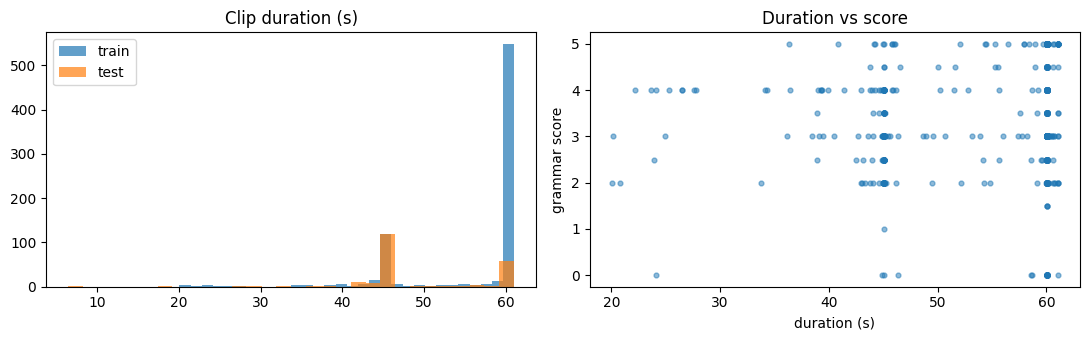

duration  train mean=55.8s  test mean=48.8s
corr(duration, score) = 0.087


In [3]:
import soundfile as sf
train["dur"] = train["path"].map(lambda p: sf.info(p).duration)
test["dur"] = test["path"].map(lambda p: sf.info(p).duration)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(train["dur"], bins=30, alpha=.7, label="train"); ax[0].hist(test["dur"], bins=30, alpha=.7, label="test")
ax[0].set_title("Clip duration (s)"); ax[0].legend()
ax[1].scatter(train["dur"], y, s=12, alpha=.5)
ax[1].set_xlabel("duration (s)"); ax[1].set_ylabel("grammar score"); ax[1].set_title("Duration vs score")
plt.tight_layout(); plt.show()
print(f"duration  train mean={train.dur.mean():.1f}s  test mean={test.dur.mean():.1f}s")
print(f"corr(duration, score) = {pearsonr(train.dur, y)[0]:.3f}")

## 2. Transcription (Whisper)

Settings that matter for *grammar*, not ASR accuracy:
* `initial_prompt` contains disfluent English. Whisper otherwise silently corrects grammar, which erases the errors we score.
* `temperature=0`, `beam_size=5`: deterministic, so re-runs give identical features.
* `condition_on_previous_text=False`: avoids repetition loops.

Transcripts are cached in `artifacts/cache/transcripts/`, so this runs once.

In [4]:
from src.transcribe import transcribe_split
tx_train = transcribe_split(CFG, train)
tx_test = transcribe_split(CFG, test)
for i in range(3):
    k = train["id"].iloc[i]
    print(f"[{k}] score={y[i]:.1f} | {tx_train[k]['text'][:200]}")

[train_audio_192] score=3.0 | Umm... Well, this, the plateland is very, very beautiful and fun. There are, there are fleas, like, the mules around the screen. The skin usually enjoy the screen. It has to be like, um, it's more lik
[train_audio_436] score=3.0 | Ah, the scene of a school playground, our playground looks like a very big playground, having a more, more greenery trees, in which way students like to garden, more trees to have a fresh year and all
[train_audio_447] score=3.5 | My favorite place to reject is the beach. I love the sound of the waves crashing against the shore. The freezing of the sandbits in my toys and the small smell of the saltwater. I love the fact that t


## 3. Feature engineering

| Family | Captures | Why it should correlate with grammar |
|---|---|---|
| Text basics | length, TTR, fillers, repetition | Richer, less repetitive speech = higher proficiency |
| spaCy syntax | clause depth, subordination, agreement and article errors | Syntactic complexity and error signals |
| LanguageTool | rule-based errors per 100 words | Explicit grammar-rule violations |
| GPT-2 surprisal | LM perplexity | Ungrammatical word order is statistically surprising |
| GEC edit rate | minimal edits to correct each sentence | Most direct proxy for "how many grammar errors" |
| Fluency | speech rate, pauses, mean length of run | Graders are influenced by smooth delivery |
| ASR confidence | Whisper log-probs | Low confidence = unclear or ungrammatical speech |
| Acoustic | MFCC, F0, energy, silence | Prosody and pronunciation |
| Embeddings | sentence semantics; WavLM hidden states | Dense signal the handcrafted features miss |

Every stage is **unsupervised**, so computing it on train and test separately cannot leak the label.

In [5]:
from src.features import build_tabular_features, build_embeddings
F_tr = build_tabular_features(CFG, train, "train", tx_train)
F_te = build_tabular_features(CFG, test, "test", tx_test)
F_tr = F_tr.loc[:, F_tr.std() > 0]          # drop constant columns
F_te = F_te[F_tr.columns]
print("tabular feature matrix:", F_tr.shape)
F_tr.describe().T[["mean", "std", "min", "max"]].round(3).head(15)

09:27:16 | WARNING | Skipping stage 'languagetool': ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.


09:27:16 | WARNING | Skipping stage 'languagetool': ModuleNotFoundError: No java install detected. Please install java to use language-tool-python.


tabular feature matrix: (769, 104)


,mean,std,min,max
txt_n_words,109.281,39.978,19.000,345.000
txt_n_sentences,7.126,5.843,1.000,117.000
txt_words_per_sent_mean,18.875,11.554,1.487,105.000
txt_words_per_sent_std,11.367,12.687,0.000,107.735
txt_words_per_sent_max,38.761,31.197,6.000,240.000
txt_ttr,0.585,0.126,0.084,0.893
txt_root_ttr,5.825,1.115,1.124,8.626
txt_mean_word_len,4.177,0.439,2.628,6.126
txt_long_word_ratio,0.157,0.069,0.007,0.475
txt_filler_rate,0.014,0.044,0.000,0.566


In [6]:
sent_tr = build_embeddings(CFG, train, "train", "sent", tx_train)
sent_te = build_embeddings(CFG, test, "test", "sent", tx_test)
print("sentence embeddings:", None if sent_tr is None else sent_tr.shape)

sentence embeddings: (769, 768)


In [7]:
ssl_tr = build_embeddings(CFG, train, "train", "ssl", tx_train)
ssl_te = build_embeddings(CFG, test, "test", "ssl", tx_test)
print("SSL embeddings:", None if ssl_tr is None else ssl_tr.shape)

SSL embeddings: (769, 1536)


## 4. Exploratory analysis: which features track the score?

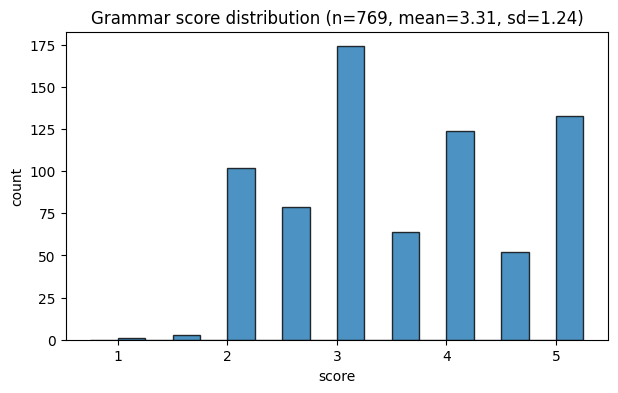

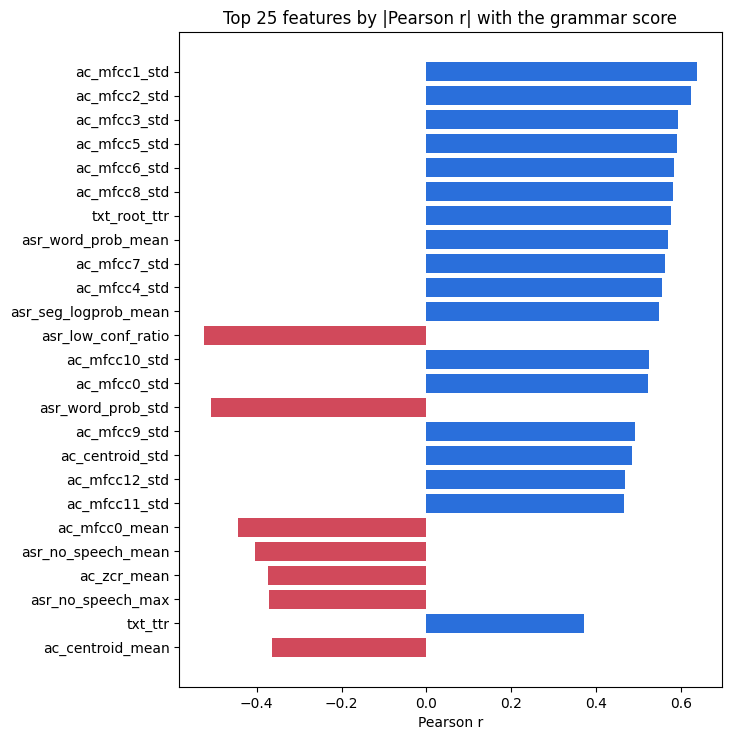

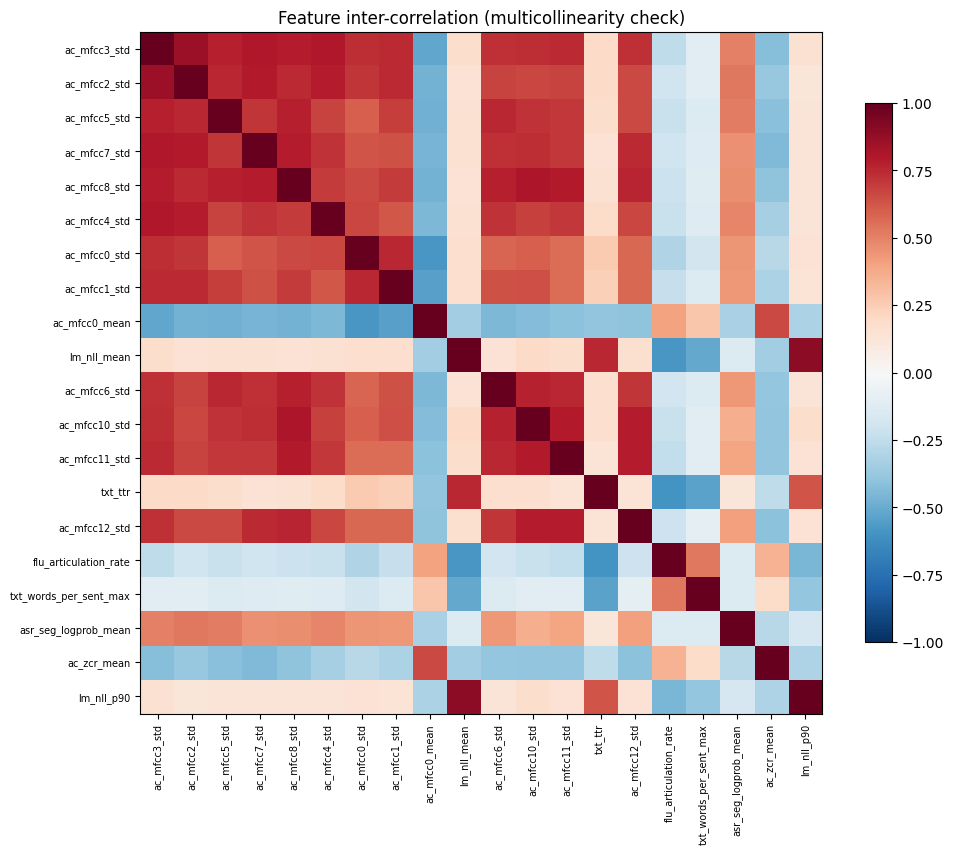

In [8]:
from src.viz import plot_correlation_with_target, plot_feature_correlation_heatmap, plot_score_distribution
plot_score_distribution(y, CFG.figure_dir / "score_distribution.png"); plt.show()
plot_correlation_with_target(F_tr, y, top=25, path=CFG.figure_dir / "feature_correlation.png"); plt.show()
plot_feature_correlation_heatmap(F_tr, top=20, path=CFG.figure_dir / "feature_intercorrelation.png"); plt.show()

## 5. Modelling with leakage-free repeated CV

* **Repeated stratified 5-fold x 3** on half-point bins: more stable than one split on 769 rows.
* Scalers, PCA and regressors live inside sklearn `Pipeline`s, so they are refit in each fold.
* OOF predictions are averaged over repeats: one honest prediction per training row.
* Blend weights are fit **on OOF predictions only**.

In [9]:
from sklearn.base import clone
from src.models import ridge_pipe, svr_pipe, embedding_pipe, gbdt_models, oof_predict, fit_full, fit_stacker
import time

specs = {
    "ridge_tab": (ridge_pipe, F_tr.to_numpy(float), F_te.to_numpy(float)),
    "svr_tab":   (svr_pipe,   F_tr.to_numpy(float), F_te.to_numpy(float)),
}
for name, proto in gbdt_models(CFG.seed).items():
    specs[f"{name}_tab"] = (lambda p=proto: clone(p), F_tr.to_numpy(float), F_te.to_numpy(float))
if sent_tr is not None:
    specs["ridge_sent"] = (embedding_pipe, sent_tr, sent_te)
if ssl_tr is not None:
    specs["ridge_ssl"] = (embedding_pipe, ssl_tr, ssl_te)

results, oof, test_pred = {}, {}, {}
for name, (mk, Xtr, Xte) in specs.items():
    t0 = time.time()
    mean, std, f_rmse, f_r = oof_predict(mk, Xtr, y, CFG)
    oof[name] = mean
    results[name] = {"OOF RMSE": rmse(y, mean), "OOF Pearson": pearson(y, mean),
                     "fold RMSE (mean±sd)": f"{f_rmse.mean():.3f}±{f_rmse.std():.3f}",
                     "sec": round(time.time() - t0, 1)}
    test_pred[name] = clip_scores(fit_full(mk, Xtr, y).predict(Xte), CFG)
pd.DataFrame(results).T

C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


...

C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


C:\Users\iamsa\AppData\Roaming\Python\Python312\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


,OOF RMSE,OOF Pearson,fold RMSE (mean±sd),sec
ridge_tab,0.70402,0.829684,0.708±0.034,0.4
svr_tab,0.759885,0.795296,0.766±0.034,0.4
catboost_tab,0.673817,0.851045,0.681±0.035,136.9
lightgbm_tab,0.676447,0.848673,0.684±0.034,10.5
ridge_sent,0.948544,0.645491,0.953±0.038,1.5
ridge_ssl,0.641939,0.864936,0.644±0.041,1.8


### 5a. Baseline check
A constant prediction (training mean) gives RMSE equal to the label standard deviation. Every model above must beat this, or it adds nothing.

In [10]:
baseline_rmse = rmse(y, np.full_like(y, y.mean()))
print(f"constant-mean baseline RMSE (train) = {baseline_rmse:.4f}")

constant-mean baseline RMSE (train) = 1.2382


## 6. Ensemble

In [11]:
names = list(oof)
O = np.column_stack([oof[n] for n in names])
T = np.column_stack([test_pred[n] for n in names])
w = fit_stacker(O, y, CFG)
blend_oof = clip_scores(np.column_stack([O, np.ones(len(y))]) @ w, CFG)
blend_test = clip_scores(np.column_stack([T, np.ones(len(T))]) @ w, CFG)
print("blend weights:", dict(zip(names + ["intercept"], np.round(w, 3))))
report = score_report(y, blend_oof, CFG)
print(f"BLEND  OOF RMSE={report['rmse']:.4f}   Pearson={report['pearson']:.4f}")

blend weights: {'ridge_tab': np.float64(0.112), 'svr_tab': np.float64(0.0), 'catboost_tab': np.float64(0.232), 'lightgbm_tab': np.float64(0.069), 'ridge_sent': np.float64(0.0), 'ridge_ssl': np.float64(0.592), 'intercept': np.float64(0.0)}
BLEND  OOF RMSE=0.6160   Pearson=0.8868


## 7. Evaluation and visualisations

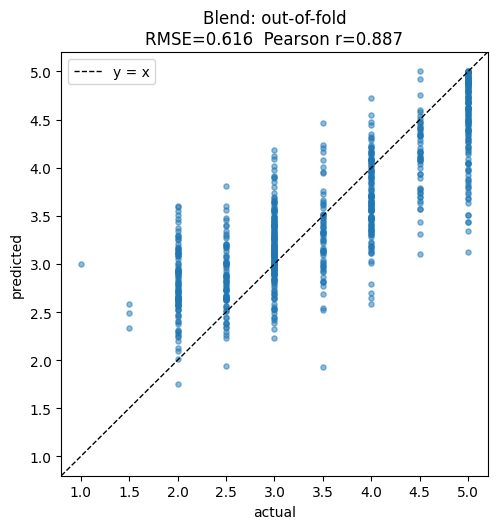

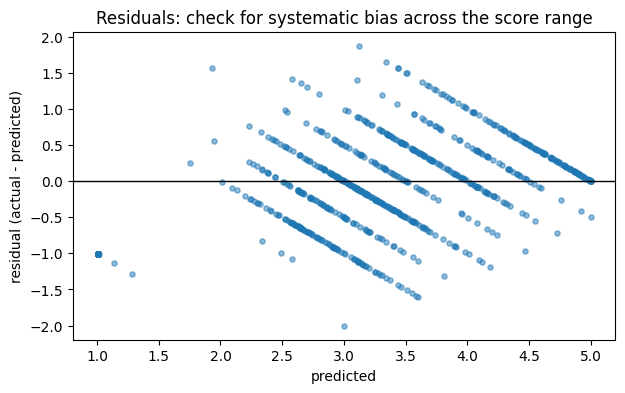

actual          1.000
ridge_ssl       0.865
catboost_tab    0.851
lightgbm_tab    0.849
ridge_tab       0.830
svr_tab         0.795
ridge_sent      0.645


In [12]:
from src.viz import plot_pred_vs_actual, plot_residuals
plot_pred_vs_actual(y, blend_oof, "Blend: out-of-fold", CFG.figure_dir / "pred_vs_actual.png"); plt.show()
plot_residuals(y, blend_oof, CFG.figure_dir / "residuals.png"); plt.show()

comp = pd.DataFrame({n: oof[n] for n in names})
comp["actual"] = y
print(comp.corr()["actual"].round(3).sort_values(ascending=False).to_string())

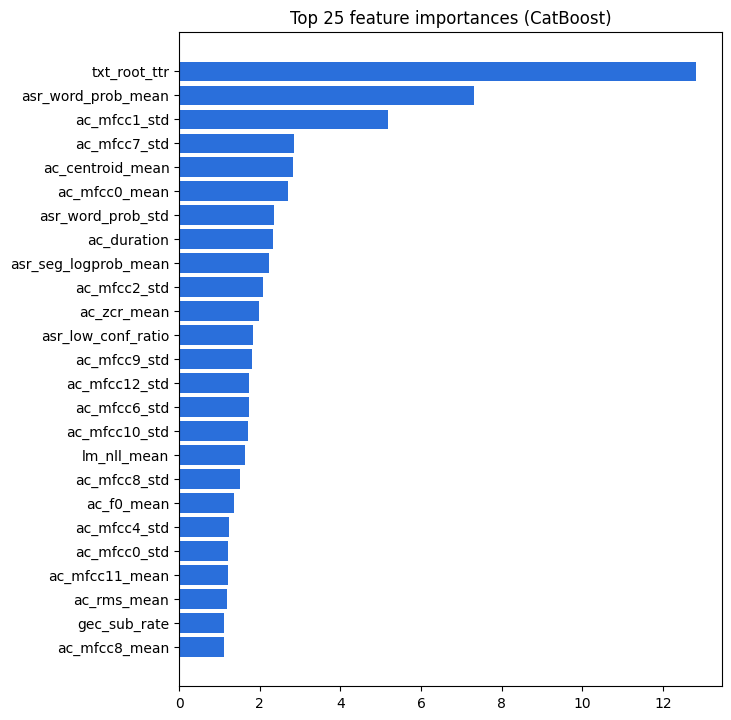

In [13]:
# Feature importance from a CatBoost fit on all training rows (interpretation only, not scoring)
from catboost import CatBoostRegressor
from src.viz import plot_feature_importance
cb = CatBoostRegressor(iterations=800, learning_rate=0.03, depth=5, verbose=0, random_seed=CFG.seed, allow_writing_files=False)
cb.fit(F_tr, y)
plot_feature_importance(F_tr.columns, cb.get_feature_importance(), top=25, path=CFG.figure_dir / "feature_importance.png")
plt.show()

## 8. Inference and submission

The same logic is used by `python -m src.inference --audio_dir <wav folder>`. For the Kaggle submission, use the blend fitted above.

In [14]:
sub = pd.DataFrame({"filename": test["filename"], "label": blend_test})
CFG.submission_path.parent.mkdir(parents=True, exist_ok=True)
sub.to_csv(CFG.submission_path, index=False)
print(sub.describe().round(3).to_string())
print("\nwrote", CFG.submission_path)

         label
count  216.000
mean     3.307
std      0.670
min      1.900
25%      2.786
50%      3.219
75%      3.681
max      5.000

wrote C:\Users\iamsa\OneDrive\Desktop\kaggle\shl-grammar-scoring\submissions\submission.csv


## 9. Summary

Report the blend's **OOF RMSE** and **Pearson r** from section 6 as the validation numbers. They are the honest estimates, since every row was predicted by models that never saw it.